<a href="https://www.savilaeducation.com/" target="_blank">
  <img src="https://res.cloudinary.com/dnq7vo3xt/image/upload/v1752564274/banner_google_collab_white_m4paih.png"
       alt="Company Banner" width="100%">
</a>


# **Handling Messy Supply Chain Data with Python**

**In this notebook you will find the code to:**

✅ Data Combination: Merged multiple Excel files and tabs with store location data (more than 400K rows).

✅ Data Cleaning: Corrected typos and handled missing values using advanced imputation techniques.

✅ Pivot tables in Python to answer business questions


**📊 Key Questions and Analysis:**

🗺️ Which region has the highest sales?

🔍 What are the top-selling SKUs per year? Spot best-performing products and track trends over time.

💸 Who are the top-selling wholesalers per year? Identify high-performing partners driving your sales.

📅 Is there a difference between sales during holidays and summer? Uncover seasonal patterns to plan promotions and inventory.

📊 What is the average number of SKUs per order? Analyze order complexity and product variety.

📦 What is the average quantity per order? Measure customer purchasing behavior to guide inventory decisions.

**📈 Visualizations and Reports You'll Create:**

📊 Bar Chart: Top-selling SKUs by year

💼 Bar Chart: Top wholesalers by year

📅 Bar-Line Chart: Sales seasonality (holidays vs. summer)

🗺️ Geovisualization Map: Regional sales performance

📂 Automatic Excel Reports: Export analysis instantly and refresh with new data

**About this version (October 2026)**

This notebook goes with the updated course files. If you downloaded the files earlier, please download them again so your results match this notebook.

- The dataset was updated after the videos were recorded. Most results are exactly the same as in the videos. The notes in this notebook point out where your output will look different.
- One small code change makes the notebook work with the latest pandas version (see the note in *Clean data and handle missing values*).

# Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
from tqdm import tqdm

# **Part 1**

# Import Data

In [2]:
# List of file names and corresponding years
files = dict()
for file in os.listdir():
  if 'supply' in file:
    year = int(file.split('.')[0].split("_")[2])
    files[file] = year
files

{'supply_data_2022.xlsx': 2022,
 'supply_data_2020.xlsx': 2020,
 'supply_data_2024.xlsx': 2024,
 'supply_data_2023.xlsx': 2023,
 'supply_data_2021.xlsx': 2021}

In [3]:
# Initialize an empty list to store DataFrames
all_data = list()

for file,year in tqdm(files.items()):
  xls = pd.ExcelFile(file)
  for month in range(1,13):
    sheet_name = f'Month_{month}'
    df = pd.read_excel(xls,sheet_name = sheet_name)
    df['Year'] = year
    df['Month'] = month
    all_data.append(df)

100%|██████████| 5/5 [00:40<00:00,  8.09s/it]


In [4]:
#joining all the data

df = pd.concat(all_data, ignore_index=True)

In [5]:
#sorting data by Year and Month

df = df.sort_values(by=['Year', 'Month'])

In [6]:
#visualizing dataset table structure, first rows of dataset

df.head()

,Date,Order_ID,SKU_Name,Quantity,Sales,Location,Year,Month
79302,2020-01-01,19b25d74-0510-4dcd-81a3-491ef06e538e,SKU-1717,32,375.04,Gauthier Jacquot S.A.S.,2020,1
79303,2020-01-01,19b25d74-0510-4dcd-81a3-491ef06e538e,SKU-7661,36,615.96,Gauthier Jacquot S.A.S.,2020,1
79304,2020-01-01,19b25d74-0510-4dcd-81a3-491ef06e538e,SKU-6001,43,402.05,Gauthier Jacquot S.A.S.,2020,1
79305,2020-01-06,fe89c540-d2fb-404e-a672-d6b0ea897e2d,SKU-6780,1,4.09,Carlier SA,2020,1
79306,2020-01-06,fe89c540-d2fb-404e-a672-d6b0ea897e2d,SKU-8445,4,19.76,Carlier SA,2020,1


In [7]:
#visualizing dataset table structure, last rows of dataset

df.tail()

,Date,Order_ID,SKU_Name,Quantity,Sales,Location,Year,Month
238894,2024-12-02,77a64d40-70e4-4332-abad-64b8741cbd9c,SKU-3852,69,1300.81,Clerc Bouvier SA,2024,12
238895,2024-12-02,77a64d40-70e4-4332-abad-64b8741cbd9c,SKU-1173,27,364.66,Clerc Bouvier SA,2024,12
238896,2024-12-02,77a64d40-70e4-4332-abad-64b8741cbd9c,SKU-7661,3,57.77,Clerc Bouvier SA,2024,12
238897,2024-12-02,77a64d40-70e4-4332-abad-64b8741cbd9c,SKU-5004,75,631.41,Clerc Bouvier SA,2024,12
238898,2024-12-26,1ce1be81-a90b-42e1-9754-987938bd5964,SKU-6682,21,466.57,Menard Gallet S.A.S.,2024,12


In [8]:
#getting the size of the dataset (rows, columns)
df.shape

(396978, 8)

# Clean data and handle missing values

In [9]:
#getting the number of missing values

df.isna().sum()

,0
Date,0
Order_ID,0
SKU_Name,0
Quantity,0
Sales,2986
Location,0
Year,0
Month,0


In [10]:
#assigning name to missing values column

df.isna().sum().reset_index().rename(columns={'index': 'Column', 0: 'Missing Values'})

,Column,Missing Values
0,Date,0
1,Order_ID,0
2,SKU_Name,0
3,Quantity,0
4,Sales,2986
5,Location,0
6,Year,0
7,Month,0


In [11]:
# Find and store all unique text values present in the 'Sales' column.
# This is important for data cleaning, as these values might represent errors
# or require special handling during analysis.

unique_text_values = []

for value in df['Sales']:
    if isinstance(value, str) and value not in unique_text_values:
        unique_text_values.append(value)

**Note on pandas versions**

Since pandas 3.0 (released in January 2026), `replace()` no longer turns the `Sales` column into numbers on its own. Without that step, the imputation further down stops with a `ZeroDivisionError`.

To make it work in every version, add `.astype(float)` at the end of the line:

```python
df['Sales'] = df['Sales'].replace(unique_text_values, np.nan).astype(float)
```

You can check your version with `pd.__version__`. With pandas 3, a few outputs also look slightly different (for example `<StringArray>` instead of `array([...])`, or `dtype: str` instead of `dtype: object`). The results are the same.

In [12]:
# Replace any non-numeric values (text errors) in the 'Sales' column with NaN (Not a Number)
# to ensure data consistency and prevent calculation errors during analysis.

df['Sales'] = df['Sales'].replace(unique_text_values, np.nan).astype(float)

/tmp/ipykernel_1578/2827788247.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Sales'] = df['Sales'].replace(unique_text_values, np.nan).astype(float)


In [13]:
#getting the total number of missing values in the sales column

df.isna().sum().reset_index().rename(columns={'index': 'Column', 0: 'Missing Values'})

,Column,Missing Values
0,Date,0
1,Order_ID,0
2,SKU_Name,0
3,Quantity,0
4,Sales,6541
5,Location,0
6,Year,0
7,Month,0


# Clean SKU's

In [14]:
#getting the unique SKUs names in the dataset

df['SKU_Name'].unique()

array(['SKU-1717', 'SKU-7661', 'SKU-6001', 'SKU-6780', 'SKU-8445',
       'SKU-2972', 'SKU-2983', 'SKU-6682', 'SKU-7054', 'SKU-3044',
       'SKU-9023', 'SKU-1173', 'SKU-7899', 'SKU-9325', 'SKU-6106',
       'SKU-5004', 'SKU-7394', 'SKU-2972_fr', 'SKU-5304', '@SKU-9325',
       'SKU-3852', 'SKU-5373', '@SKU-7899', '@SKU-2983', 'SKU-7899_fr',
       '@SKU-6001', '@SKU-6780', 'SKU-6682_fr', '@SKU-3852',
       'SKU-9325_fr', '@SKU-1173', 'SKU-6780_fr', 'SKU-7394_fr',
       '@SKU-5373', '@SKU-2972', '@SKU-6106', 'SKU-5304_fr',
       'SKU-3852_fr', 'SKU-9023_fr', '@SKU-9023', '@SKU-7054',
       '@SKU-5004', '@SKU-7394', '@SKU-5304', '@SKU-6682', '@SKU-3044',
       '@SKU-7661', 'SKU-5004_fr', 'SKU-7054_fr', '@SKU-8445',
       'SKU-1717_fr', 'SKU-6106_fr', '@SKU-1717', 'SKU-6001_fr',
       'SKU-8445_fr', 'SKU-7661_fr', 'SKU-3044_fr', 'SKU-5373_fr',
       'SKU-2983_fr', 'SKU-1173_fr'], dtype=object)

In [15]:
# identifying inconsistency in SKU names

df[df['SKU_Name'].str.contains('SKU-6001', na=False)]['SKU_Name'].unique()

array(['SKU-6001', '@SKU-6001', 'SKU-6001_fr'], dtype=object)

In [16]:
#function to fix SKU names

def fix_sku_name(x):

    return x.replace('@','').replace('_fr','')

In [17]:
fix_sku_name('SKU-6001_fr')

'SKU-6001'

In [18]:
fix_sku_name('@SKU-6001')

'SKU-6001'

In [19]:
df['SKU_Name'] = df['SKU_Name'].apply(fix_sku_name)

In [20]:
df[df['SKU_Name'].str.contains('SKU-6001', na=False)]['SKU_Name'].unique()

array(['SKU-6001'], dtype=object)

In [21]:
df['SKU_Name'].unique()

array(['SKU-1717', 'SKU-7661', 'SKU-6001', 'SKU-6780', 'SKU-8445',
       'SKU-2972', 'SKU-2983', 'SKU-6682', 'SKU-7054', 'SKU-3044',
       'SKU-9023', 'SKU-1173', 'SKU-7899', 'SKU-9325', 'SKU-6106',
       'SKU-5004', 'SKU-7394', 'SKU-5304', 'SKU-3852', 'SKU-5373'],
      dtype=object)

# Smart data inputation

- Look for the sales and quantity of the same SKU in the same year, in orders that do not have missing values,
- then calculate the price per unit of the SKU on that year,
- Using the quantity on the order with the missing value and the estimated price, calculate sales.


In [22]:
# Get the row indices of all rows where the 'Sales' column has missing values.
# These indices will be used later to impute (fill in) the missing sales data.

missing_sales_indices = df[df['Sales'].isna()].index

In [23]:
missing_sales_indices

Index([ 79386,  79419,  79459,  79511,  79594,  79602,  79748,  79796,  79824,
        79847,
       ...
       237737, 237739, 237830, 238458, 238499, 238515, 238516, 238549, 238613,
       238688],
      dtype='int64', length=6541)

In [24]:
len(missing_sales_indices)

6541

In [25]:
# Impute missing sales values using smart data imputation

for idx in tqdm(missing_sales_indices):
     # Extract relevant information for the current row
    year = df.loc[idx, 'Year']
    sku = df.loc[idx, 'SKU_Name']
    quantity = df.loc[idx, 'Quantity']

    # Filter the DataFrame for the same year and SKU, excluding missing sales
    relevant_data = df[(df['Year'] == year) & (df['SKU_Name'] == sku) & (df['Sales'].notna())]

    # If similar orders are found, impute the missing sales value
    if not relevant_data.empty:
      price_per_unit = (relevant_data['Sales'] / relevant_data['Quantity']).mean()

      # Impute the missing sales value
      df.loc[idx, 'Sales'] = price_per_unit * quantity

100%|██████████| 6541/6541 [05:37<00:00, 19.39it/s]


In [26]:
#checking that the missing values were replaced with the data imputation method

df.isna().sum().reset_index().rename(columns={'index': 'Column', 0: 'Missing Values'})

,Column,Missing Values
0,Date,0
1,Order_ID,0
2,SKU_Name,0
3,Quantity,0
4,Sales,0
5,Location,0
6,Year,0
7,Month,0


# Join client location data

In [27]:
#creating a dataframe for the location stores data

location_df = pd.read_excel('stores.xlsx')

In [28]:
location_df.head()

,location,city,lat,lng,region
0,Rolland,Le Havre,49.4900,0.1000,Normandie
1,Reynaud S.A.,Strasbourg,48.5833,7.7458,Grand Est
2,Girard,Paris,48.8567,2.3522,Île-de-France
3,Martel,Lille,50.6278,3.0583,Hauts-de-France
4,Perret,Paris,48.8567,2.3522,Île-de-France


In [29]:
#checking structure of dataframe supply data

df.head()

,Date,Order_ID,SKU_Name,Quantity,Sales,Location,Year,Month
79302,2020-01-01,19b25d74-0510-4dcd-81a3-491ef06e538e,SKU-1717,32,375.04,Gauthier Jacquot S.A.S.,2020,1
79303,2020-01-01,19b25d74-0510-4dcd-81a3-491ef06e538e,SKU-7661,36,615.96,Gauthier Jacquot S.A.S.,2020,1
79304,2020-01-01,19b25d74-0510-4dcd-81a3-491ef06e538e,SKU-6001,43,402.05,Gauthier Jacquot S.A.S.,2020,1
79305,2020-01-06,fe89c540-d2fb-404e-a672-d6b0ea897e2d,SKU-6780,1,4.09,Carlier SA,2020,1
79306,2020-01-06,fe89c540-d2fb-404e-a672-d6b0ea897e2d,SKU-8445,4,19.76,Carlier SA,2020,1


In [30]:
# renaming Location columns to match datasets

location_df = location_df.rename(columns = {'location':'Location'})

In [31]:
#merging the 2 datasets by the "Location" column
#now df contains the supply_data and stores data

df = df.merge(location_df, on='Location', how='left')

In [32]:
df.head()

,Date,Order_ID,SKU_Name,Quantity,Sales,Location,Year,Month,city,lat,lng,region
0,2020-01-01,19b25d74-0510-4dcd-81a3-491ef06e538e,SKU-1717,32,375.04,Gauthier Jacquot S.A.S.,2020,1,Bordeaux,44.84,-0.58,Nouvelle-Aquitaine
1,2020-01-01,19b25d74-0510-4dcd-81a3-491ef06e538e,SKU-7661,36,615.96,Gauthier Jacquot S.A.S.,2020,1,Bordeaux,44.84,-0.58,Nouvelle-Aquitaine
2,2020-01-01,19b25d74-0510-4dcd-81a3-491ef06e538e,SKU-6001,43,402.05,Gauthier Jacquot S.A.S.,2020,1,Bordeaux,44.84,-0.58,Nouvelle-Aquitaine
3,2020-01-06,fe89c540-d2fb-404e-a672-d6b0ea897e2d,SKU-6780,1,4.09,Carlier SA,2020,1,Lyon,45.76,4.84,Auvergne-Rhône-Alpes
4,2020-01-06,fe89c540-d2fb-404e-a672-d6b0ea897e2d,SKU-8445,4,19.76,Carlier SA,2020,1,Lyon,45.76,4.84,Auvergne-Rhône-Alpes


In [33]:
#checking for missing values

df.isna().sum().reset_index().rename(columns={'index': 'Column', 0: 'Missing Values'})

,Column,Missing Values
0,Date,0
1,Order_ID,0
2,SKU_Name,0
3,Quantity,0
4,Sales,0
5,Location,0
6,Year,0
7,Month,0
8,city,0
9,lat,0


# **Answering sales questions**


## What is the region with the top sales

**Note:** The dataset was updated after the videos were recorded. Auvergne-Rhône-Alpes is still the region with the top sales, but the amount for each region is slightly different from the one shown in the video.

In [34]:
# Create a pivot table to calculate total sales per region

df.pivot_table(
    values= 'Sales', # Values to aggregate (sales in this case)
    index = 'region', # Column to group by (region)
    aggfunc = 'sum', # Aggregation function (sum of sales)
    fill_value= 0    # Fill missing values with 0
).sort_values(by = 'Sales',ascending = False).reset_index() # Sort by total sales and reset index

,region,Sales
0,Auvergne-Rhône-Alpes,2.502907e+07
1,Provence-Alpes-Côte d’Azur,1.961794e+07
2,Occitanie,1.840690e+07
3,Grand Est,1.195309e+07
4,Pays de la Loire,1.032025e+07
5,Île-de-France,9.028421e+06
6,Bretagne,8.329981e+06
7,Normandie,8.022298e+06
8,Bourgogne-Franche-Comté,7.609821e+06
9,Nouvelle-Aquitaine,5.026297e+06


In [35]:
#getting the region with top sales
df.pivot_table(
    values= 'Sales', # Values to aggregate (sales in this case)
    index = 'region', # Column to group by (region)
    aggfunc = 'sum', # Aggregation function (sum of sales)
    fill_value= 0    # Fill missing values with 0
).idxmax() #identifying the region with top sales

,0
Sales,Auvergne-Rhône-Alpes


In [36]:
# getting the amount of sales of the top region
df.pivot_table(
    values= 'Sales',
    index = 'region',
    aggfunc = 'sum',
    fill_value= 0
).sort_values(by = 'Sales',ascending = False).iloc[0,:]

,Auvergne-Rhône-Alpes
Sales,2.502907e+07


## What is the city with the top sales?

In [37]:
df.pivot_table(
    values="Sales",
    index="city",
    aggfunc="sum",
    fill_value=0
).sort_values(by='Sales', ascending=False)

,Sales
city,
Saint-Étienne,1.054779e+07
Nice,1.012302e+07
Nîmes,9.584239e+06
Paris,9.028421e+06
Rennes,8.329981e+06
Le Havre,8.022298e+06
Dijon,7.609821e+06
Reims,7.460973e+06
Lyon,6.560008e+06


In [38]:
df.pivot_table(
    values="Sales",
    index="city",
    aggfunc="sum",
    fill_value=0
).idxmax()

,0
Sales,Saint-Étienne


In [39]:
df.pivot_table(
    values="Sales",
    index="city",
    aggfunc="sum",
    fill_value=0
).idxmin()

,0
Sales,Lille


# **Bonus questions about pandas**

## How can I save one of my tables in an excel file?

Suppose we want to save the results of a pivot table that aggregates sales per region. We can store the table in a variable, such as regional_sales, and then use the ```.to_excel()``` method from Pandas to save it to a file.

To do this, we simply provide the desired filename along with the appropriate file extension. For example:

In [40]:
regional_sales = df.pivot_table(
    values= 'Sales',
    index = 'region',
    aggfunc = 'sum',
    fill_value= 0
).sort_values(by = 'Sales',ascending = False).reset_index()

# Save the 'regional_sales' DataFrame to an Excel file
# The file will be named 'regional_sales.xlsx' and the index will not be included

regional_sales.to_excel('regional_sales.xlsx', index= False)

## What happens if I dont know the name of the sheets in advance?

It's common to encounter Excel files with a different number of sheets, especially when dealing with messy or inconsistently formatted data. In some cases, the sheet names may not follow a structured naming convention, making it challenging to process them systematically. So, how can we handle this situation?

When importing an Excel file using ```pd.ExcelFile('excel_file_name_here.xlsx')```, we can access the ```.sheet_names``` attribute. This returns a list containing the names of all sheets in the file, allowing us to dynamically identify and work with them.

In [41]:
# get the sheet names of the excel file corresponding to 2022

pd.ExcelFile('supply_data_2022.xlsx').sheet_names

['Month_1',
 'Month_2',
 'Month_3',
 'Month_4',
 'Month_5',
 'Month_6',
 'Month_7',
 'Month_8',
 'Month_9',
 'Month_10',
 'Month_11',
 'Month_12']

### DO NOT RUN THIS CODE HERE – It will overwrite the work done at the beginning of this notebook.

Example:
This code below is designed to read data from multiple Excel files where:



*   Each file represents a year of sales data.
*   Each file can have a different number of sheets, potentially representing only a portion of the year (e.g., six months).

*   Sheet names are assumed to follow a pattern like "Month_1", "Month_2", etc.


By dynamically getting the sheet names using xls.sheet_names, the code can adapt to different numbers of sheets in each file. If a file has only data for six months, the loop will only iterate through those six sheet names, preventing errors that might occur if the code expected a full 12 months of data.


```{python}
all_data = list()

for file,year in tqdm(files.items()):
  xls = pd.ExcelFile(file)
  sheet_names = xls.sheet_names
  for sheet in sheet_names:
    month = int(sheet.split("_")[1])
    df = pd.read_excel(xls,sheet_name = sheet)
    df['Year'] = year
    df['Month'] = month
    all_data.append(df)
```

## How to change the style o the pandas dataframe?

For example, let's say we want to format the Sales column to display values without decimals, use a comma as a thousands separator, and include the € currency symbol to ensure clarity.

We can achieve this easily using the style attributes of a DataFrame and modifying the column format with ```df.style.format()```. Inside the format() method, we pass a dictionary specifying the columns to modify and the desired formatting.

In [42]:
regional_sales.style.format({'Sales': '{:,.0f} €'})

,region,Sales
0,Auvergne-Rhône-Alpes,"25,029,069 €"
1,Provence-Alpes-Côte d’Azur,"19,617,940 €"
2,Occitanie,"18,406,897 €"
3,Grand Est,"11,953,085 €"
4,Pays de la Loire,"10,320,251 €"
5,Île-de-France,"9,028,421 €"
6,Bretagne,"8,329,981 €"
7,Normandie,"8,022,298 €"
8,Bourgogne-Franche-Comté,"7,609,821 €"
9,Nouvelle-Aquitaine,"5,026,297 €"


Please note that Pandas styling is highly versatile, allowing you to customize tables as needed. For example, you can modify **header** properties, **cell** properties, and more.

In [43]:
headers = {
    "selector": "th:not(.index_name)",
    "props": "background-color: #800000; color: white; text-align: center"
}
properties = {"border": "1px solid black", "width": "200px", "text-align": "center"}

name_cell = {'selector': '',
            'props': "background-color: #281E5D; color: white; text-align: center"}

regional_sales.style.format({'Sales': '{:,.0f} €'}).\
set_table_styles([headers]).set_properties(**properties).\
set_table_styles({'region': [name_cell]}, overwrite=False).\
highlight_min(subset = 'Sales',color = 'red').\
highlight_max(subset = 'Sales',color = 'green')

,region,Sales
0,Auvergne-Rhône-Alpes,"25,029,069 €"
1,Provence-Alpes-Côte d’Azur,"19,617,940 €"
2,Occitanie,"18,406,897 €"
3,Grand Est,"11,953,085 €"
4,Pays de la Loire,"10,320,251 €"
5,Île-de-France,"9,028,421 €"
6,Bretagne,"8,329,981 €"
7,Normandie,"8,022,298 €"
8,Bourgogne-Franche-Comté,"7,609,821 €"
9,Nouvelle-Aquitaine,"5,026,297 €"


# **Part 2**

# **Answering more complex questions**

## Top SKU's

What are the Top selling SKU's per year?

In [44]:
# Create a pivot table to summarize sales data by SKU and year.
# The resulting table will be stored in the 'sales_sku_pivot' DataFrame.

sales_sku_pivot = df.pivot_table(
    values="Sales",   # The values to aggregate (sum in this case) come from the 'Sales' column.
    index="SKU_Name", # Rows of the pivot table will be organized by unique 'SKU_Name' values.
    columns="Year",   # Columns of the pivot table will be organized by unique 'Year' values.
    aggfunc="sum",    # The aggregation function is 'sum', calculating total sales for each SKU/year.
    fill_value=0      # Fill any missing SKU/year combinations with 0 sales.
)

In [45]:
#sales_sku_pivot

In [46]:
# Get the SKU with the highest sales for each year.
top_skus_per_year = sales_sku_pivot.idxmax()

# Get the maximum sales value for each year.
top_sales_per_year = sales_sku_pivot.max()

In [47]:
# Combine into a DataFrame for better readability
top_sku_sellers = pd.DataFrame({
    'Top SKU': top_skus_per_year,
    'Total Sales': top_sales_per_year
})

In [48]:
top_sku_sellers = top_sku_sellers.reset_index()

In [49]:
top_sku_sellers

,Year,Top SKU,Total Sales
0,2020,SKU-6682,2.151660e+06
1,2021,SKU-3044,2.159726e+06
2,2022,SKU-6682,2.214864e+06
3,2023,SKU-3044,2.320167e+06
4,2024,SKU-6682,2.319490e+06


## Top Wholesaler

What are the top selling wholesalers per year?

In [50]:
sales_wholesalers_pivot = df.pivot_table(
    values="Sales",
    index="Location",
    columns="Year",
    aggfunc="sum",
    fill_value=0
)

In [51]:
top_seller_per_year = sales_wholesalers_pivot.idxmax()
top_seller_sales_per_year = sales_wholesalers_pivot.max()

In [52]:
# Combine into a DataFrame for better readability
top_wholesalers = pd.DataFrame({
    'Top Seller': top_seller_per_year,
    'Total Sales': top_seller_sales_per_year
})

In [53]:
top_wholesalers = top_wholesalers.reset_index()

In [54]:
top_wholesalers

,Year,Top Seller,Total Sales
0,2020,Gauthier,652197.030000
1,2021,Marty,661752.078062
2,2022,Marty,670099.378284
3,2023,Gauthier,680380.554919
4,2024,Marty,668061.562080


In [55]:
# Format 'Total Sales' column to display two decimal places
top_wholesalers['Total Sales'] = top_wholesalers['Total Sales'].map('{:.2f}'.format)
top_wholesalers

,Year,Top Seller,Total Sales
0,2020,Gauthier,652197.03
1,2021,Marty,661752.08
2,2022,Marty,670099.38
3,2023,Gauthier,680380.55
4,2024,Marty,668061.56


## Seasonality

Is there any difference between sales during December holidays and summer?

**Note:** In the video, the difference between the holiday months and the summer months is called "an order of magnitude". The ratio calculated below gives the precise answer: November and December sell about 1.9 times more than June, July and August, so almost double.

In [56]:
# Create a pivot table to summarize sales by month
monthly_df = df.pivot_table(
    values="Sales",
    index="Month",
    aggfunc="sum",
    fill_value=0
).reset_index()

In [57]:
# Convert the 'Month' column to datetime objects and extract the month name
monthly_df['Month_name'] = pd.to_datetime(monthly_df['Month'], format='%m').dt.strftime('%B')

In [58]:
# Reorder the columns to have 'Month', 'Month_name', and 'Sales'
monthly_df = monthly_df[['Month','Month_name','Sales']]

In [59]:
monthly_df

,Month,Month_name,Sales
0,1,January,1.002430e+07
1,2,February,1.014770e+07
2,3,March,1.009007e+07
3,4,April,1.025372e+07
4,5,May,1.022235e+07
5,6,June,8.177046e+06
6,7,July,8.094236e+06
7,8,August,7.956902e+06
8,9,September,1.021176e+07
9,10,October,1.015589e+07


In [60]:
#monthly_df.head()

In [61]:
# Calculate the average sales during the winter holiday season (November and December)
winter_sales = monthly_df[monthly_df['Month'].isin([11,12])]['Sales'].mean()

# Calculate the average sales during the summer months (June, July, August)
summer_sales = monthly_df[monthly_df['Month'].isin([6,7,8])]['Sales'].mean()

# Calculate and print the ratio of holiday sales to summer sales
print(f'Ratio Winter and Summer sales = {winter_sales/summer_sales:0.2f}')

Ratio Winter and Summer sales = 1.86


## Average amount SKU's per order

In [62]:
# Calculate the average number of SKUs per order
df.pivot_table(
    values = 'SKU_Name', # The column to count (SKU_Name in this case)
    index = 'Order_ID',  # The column to group by (Order_ID)
    aggfunc = 'count',   # The aggregation function to use (count)
    fill_value = 0
).mean().round(0)       # Calculate the mean and round to 0 decimal places

,0
SKU_Name,7.0


## Average amount of quantity per order

In [63]:
# Calculate the average quantity of items per order

df.pivot_table(
    values = 'Quantity',
    index = 'Order_ID',
    aggfunc = 'sum',     # The aggregation function to use (sum)
    fill_value = 0
).mean().round()        # Calculate the mean and round to the nearest integer

,0
Quantity,173.0


# Visualizations

Please note that we already imported the necessary libraries at the beginning of this notebook, so there is no need to repeat them here. It is best practice to import all commonly used libraries at the start of your notebook.

```
import matplotlib.pyplot as plt
```



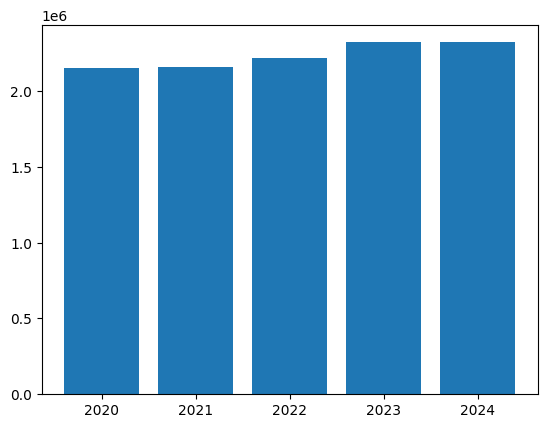

In [64]:
# Create a figure and an axes object for the plot (the white canvas)
fig, ax = plt.subplots()

# Create a bar plot using the 'ax' object.

bars = ax.bar(x= top_sku_sellers['Year'], height=top_sku_sellers['Total Sales'])

# Display the plot
plt.show()

In [65]:
import matplotlib.image as image
import matplotlib.ticker as mticker

## SKU's Bar chart

In [66]:
im = image.imread('savila_logo.png')

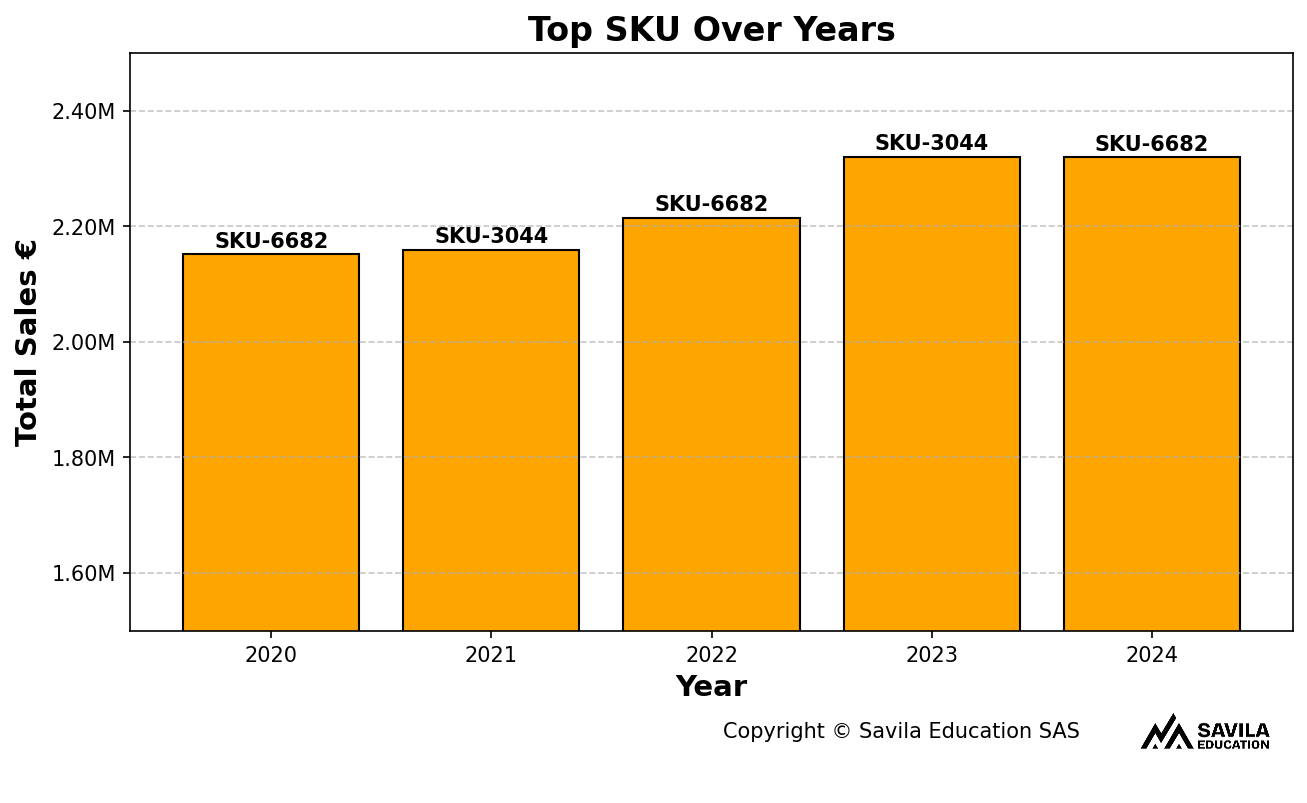

In [67]:
# Create the bar plot
fig, ax = plt.subplots(figsize=(10, 5),dpi = 150)
bars = ax.bar(top_sku_sellers['Year'], top_sku_sellers['Total Sales'],color = 'orange', edgecolor='black')

# Add seller names on top of each bar
for bar, seller in zip(bars, top_sku_sellers['Top SKU']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5000, seller,
            ha='center', va='bottom', fontsize=10, fontweight='bold')

# Set the y-axis limits for better visualization
ax.set_ylim(1.5e6,2.5e6)

# --- Adding a logo and copyright ---
# Define the position and size parameters for the logo
image_xaxis = 0.77
image_yaxis = -0.1
image_width = 0.15
image_height = 0.15

# Define the position for the image axes
ax_image = fig.add_axes([image_xaxis,
                         image_yaxis,
                         image_width,
                         image_height]
                       )
ax_image.imshow(im)  # Display the logo image
ax_image.axis('off') # Turn off axes for the logo

# Add copyright text next to the logo
fig.text(image_xaxis - image_width - 0.1, image_yaxis + image_height / 2,
         "Copyright © Savila Education SAS", fontsize=10, ha='left', va='center')

# --- Formatting the y-axis ---
# Function to format y-axis in Millions (€)
def millions_formatter(x, pos):
    return f'{x/1e6:.2f}M'  # Convert to millions

# Apply the custom formatter to the y-axis
ax.yaxis.set_major_formatter(mticker.FuncFormatter(millions_formatter))

# --- Labels and formatting for the plot ---
ax.set_xlabel("Year", fontsize=14, fontweight="bold")  # Set the x-axis label
ax.set_ylabel("Total Sales €", fontsize=14, fontweight="bold")  # Set the y-axis label
ax.set_xticks(top_sku_sellers['Year'])  # Set x-axis ticks to the years in the data, ensure years are correctly displayed

ax.set_title("Top SKU Over Years", fontsize=16, fontweight="bold")  # Set the plot title
ax.grid(axis='y', linestyle='--', alpha=0.7)  # Add a grid to the y-axis

# Save the plot to a file
plt.savefig("top_sku_sales.png", bbox_inches="tight")

# Display the plot
plt.show()

## Seller's Bar chart

In [68]:
top_wholesalers

,Year,Top Seller,Total Sales
0,2020,Gauthier,652197.03
1,2021,Marty,661752.08
2,2022,Marty,670099.38
3,2023,Gauthier,680380.55
4,2024,Marty,668061.56


In [69]:
#top_wholesalers['Total Sales'].dtype

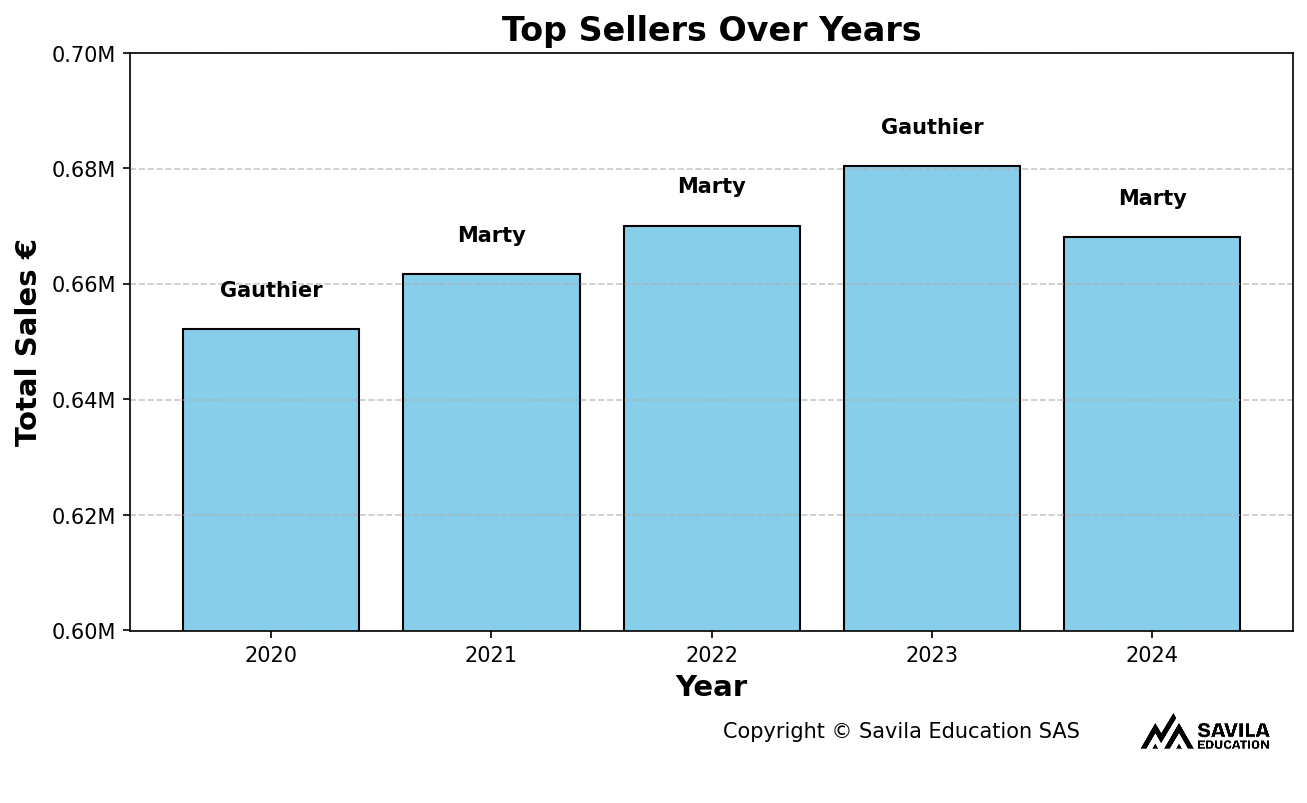

In [70]:
# Create the bar plot
fig, ax = plt.subplots(figsize=(10, 5),dpi = 150)

# Convert 'Total Sales' to numeric
top_wholesalers['Total Sales'] = pd.to_numeric(top_wholesalers['Total Sales'])


bars = ax.bar(top_wholesalers['Year'], top_wholesalers['Total Sales'],color = 'skyblue', edgecolor='black')

# Add seller names on top of each bar
for bar, seller in zip(bars, top_wholesalers['Top Seller']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+ 5000, seller,
            ha='center', va='bottom', fontsize=10, fontweight='bold')

# Set the y-axis limits for better visualization
ax.set_ylim(6e5,7e5)

# --- Adding a logo and copyright ---
# Define the position and size parameters for the logo
image_xaxis = 0.77
image_yaxis = -0.1
image_width = 0.15
image_height = 0.15

# Define the position for the image axes
ax_image = fig.add_axes([image_xaxis,
                        image_yaxis,
                        image_width,
                        image_height]
                      )

ax_image.imshow(im)  # Display the logo image
ax_image.axis('off') # Turn off axes for the logo

# Add copyright text next to the logo
fig.text(image_xaxis - image_width - 0.1, image_yaxis + image_height / 2,
        "Copyright © Savila Education SAS", fontsize=10, ha='left', va='center')


# Apply the custom function millions_formatter to the y-axis (created in the previous plot)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(millions_formatter))

# Labels and formatting
ax.set_xlabel("Year", fontsize=14, fontweight="bold")
ax.set_ylabel("Total Sales €", fontsize=14, fontweight="bold")
ax.set_xticks(top_wholesalers['Year'])  # Ensure years are correctly displayed

ax.set_title("Top Sellers Over Years", fontsize=16, fontweight="bold")
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.savefig("top_wholesalers_sales.png", bbox_inches="tight")

plt.show()

## Seasonality Bar-Line chart



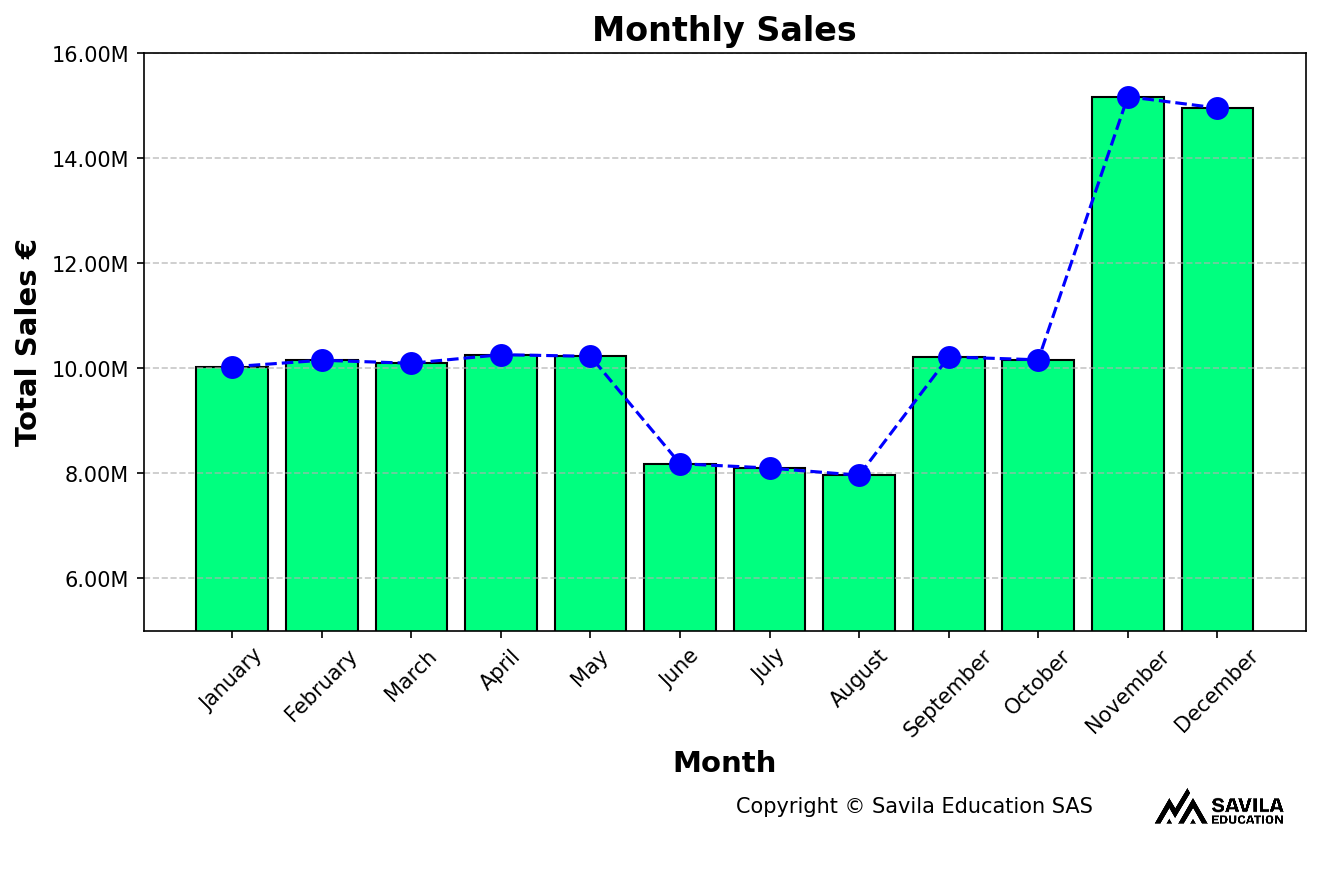

In [71]:
# Create a bar plot to show monthly sales
fig, ax = plt.subplots(figsize=(10, 5),dpi = 150)
bars = ax.bar(monthly_df['Month'], monthly_df['Sales'],
              color = 'springgreen', edgecolor='black')


# Overlay a line plot on top of the bars to highlight the trend
ax.plot(monthly_df['Month'], monthly_df['Sales'], color='blue',
        linestyle='--',marker = 'o', markersize=10)

# Set the y-axis limits to ensure all data is visible
ax.set_ylim(5e6,16e6)

# --- Adding a logo and copyright ---
# Define the position and size for the logo
image_xaxis = 0.77
image_yaxis = -0.2
image_width = 0.15
image_height = 0.15

# Define the position for logo axes
ax_image = fig.add_axes([image_xaxis,
                         image_yaxis,
                         image_width,
                         image_height]
                       )

ax_image.imshow(im) # Display the logo image
ax_image.axis('off') # Turn off axes for the logo

# Add copyright text next to the logo
fig.text(image_xaxis - image_width - 0.1, image_yaxis + image_height / 2,
         "Copyright © Savila Education SAS", fontsize=10, ha='left', va='center')

# --- Formatting the y-axis ---
# Apply the custom function million formatter to the y-axis (created in the previous plot)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(millions_formatter))

# --- Formatting the x-axis ---
# Set custom x-axis ticks with month names and rotate them for readability
ax.set_xticks(monthly_df['Month'],monthly_df['Month_name'],rotation = 45)

# --- Labels and formatting for the plot ---
ax.set_xlabel("Month",fontsize=14, fontweight="bold" )          # Set x-axis label with styling
ax.set_ylabel("Total Sales €", fontsize=14, fontweight="bold")  # Set y-axis label with styling
ax.set_xticks(monthly_df['Month'])


ax.set_title("Monthly Sales", fontsize=16, fontweight="bold") # Set plot title
ax.grid(axis='y', linestyle='--', alpha=0.7) # Add a grid to the y-axis

# Save the plot to a file .png
plt.savefig("monthly_sales.png", bbox_inches="tight")


# Display the plot
plt.show()

## France Regional Sales Map Using GeoPandas

**Note:** The bubble sizes and colours on your map may differ slightly from the video, because the dataset was updated after the recording. Auvergne-Rhône-Alpes is still the largest bubble.

In [72]:
import matplotlib.colors as mcolors
import geopandas as gpd

In [73]:
gdf = gpd.read_file('countries_maps.zip')
gdf = gdf.rename(columns={'ADMIN': 'name'})

In [74]:
france = gdf[(gdf['name'] == 'France')]

In [75]:
regions_total_df = df.pivot_table(
    values = ['Sales','lat','lng'],
    index = 'region',
    aggfunc = {'Sales':'sum','lat':'mean','lng':'mean'},
    fill_value = 0
).reset_index()

In [76]:
# Normalize sales for bubble sizes
max_sales = regions_total_df['Sales'].max()
regions_total_df['size'] = (regions_total_df['Sales'] / max_sales) * 1000  # Adjust scaling factor

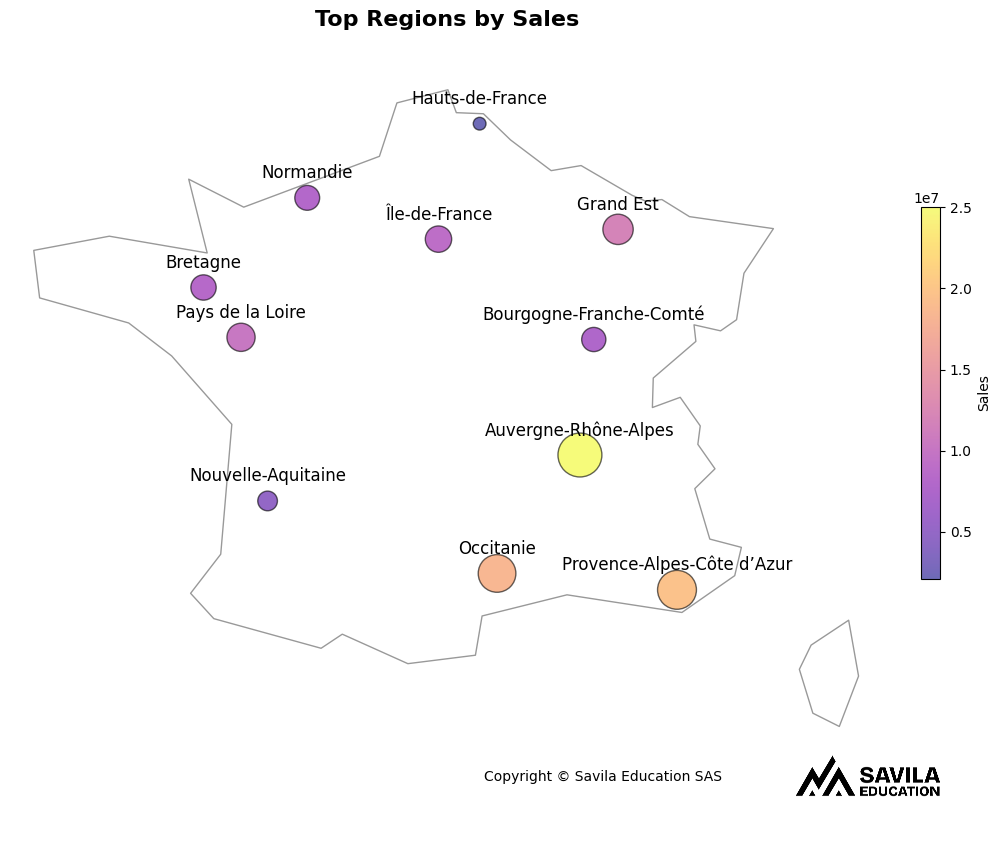

In [77]:
# Define colormap
norm = mcolors.Normalize(vmin=regions_total_df['Sales'].min(), vmax=regions_total_df['Sales'].max())
cmap = plt.get_cmap('plasma')

# Explicitly create figure and axis
fig, ax = plt.subplots(figsize=(12, 12))

# Plotting
# ax = france.plot(color='white', edgecolor='black', alpha=0.6,figsize=(12, 12))
france.plot(ax=ax, color='white', edgecolor='black', alpha=0.4)
ax.set_xlim(-5, 10)
ax.set_ylim(41, 52)

# Plot sales bubbles with color mapping
scatter = ax.scatter(regions_total_df['lng'], regions_total_df['lat'],
                     s=regions_total_df['size'], alpha=0.6,
                     c=regions_total_df['Sales'], cmap=cmap, edgecolor='black')

# Create a legend for bubble sizes
for sales_value in [1e6, 1e7, 2.5e7]:  # Example values for the scale
    plt.scatter([], [], s=(sales_value / max_sales) * 100, c='gray', alpha=0.6,
                label=f'{int(sales_value)/1e6:.0f}M€')

# Annotate region names
for i, row in regions_total_df.iterrows():
    plt.annotate(row['region'], xy=(row['lng'], row['lat'] + 0.3),
                 ha='center', fontsize=12,fontweight='normal')

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax, fraction=0.02, pad=0.04)
cbar.set_label('Sales')


plt.title('Top Regions by Sales', fontsize=16, fontweight="bold") # plot title


ax.axis('off') # Turn off axes for plot


# --- Adding a logo and copyright ---
# Define the position and size for the logo
image_xaxis = 0.77
image_yaxis = 0.1
image_width = 0.15
image_height = 0.15

# Define the position for logo axes
ax_image = fig.add_axes([image_xaxis,
                         image_yaxis,
                         image_width,
                         image_height]
                       )

ax_image.imshow(im) # Display the logo image
ax_image.axis('off') # Turn off axes for the logo

# Add copyright text next to the logo
fig.text(image_xaxis - image_width - 0.1, image_yaxis + image_height / 2,
         "Copyright © Savila Education SAS", fontsize=10, ha='left', va='center')

plt.savefig("regional_sales.png", bbox_inches="tight")
plt.show()

# Automatic Excel Reporting

In [78]:
!pip install XlsxWriter

In [79]:
with pd.ExcelWriter("sales_summary.xlsx", engine="xlsxwriter") as writer:
    workbook = writer.book  # Get workbook

    # Define the currency format (Euro, thousand separator, no decimals)
    currency_format = workbook.add_format({'num_format': '€#,##0', 'align': 'right'})


    # ---- Top SKUs ---- #
     # Writing top_sku_seller summary at A1 in "Top Sellers" tab
    top_sku_sellers.to_excel(writer, sheet_name="Top SKUs", index=False, startrow=1, startcol=1)
    worksheet_skus = writer.sheets["Top SKUs"]

    col_idx_sku = top_sku_sellers.columns.get_loc("Total Sales") + 1  # Adjust for zero-based index
    worksheet_skus.set_column(col_idx_sku, col_idx_sku, 15, currency_format)

    # Adding the top sellers chart to cell F2
    worksheet_skus.insert_image("F2", "top_sku_sales.png")

    # ---- Top Sellers ---- #
    # Writing top seller summary at A1 in "Top Sellers" tab
    top_wholesalers.to_excel(writer, sheet_name="Top Sellers", index=False, startrow=1, startcol=1)

    # Selecting "Top Sellers" tab
    worksheet_sellers = writer.sheets["Top Sellers"]

    # Apply currency format to the "Sales" column (assuming it's column C)
    col_idx_sales = top_wholesalers.columns.get_loc("Total Sales") + 1  # Adjust for zero-based index
    worksheet_sellers.set_column(col_idx_sales, col_idx_sales, 15, currency_format)

    # Adding the top sellers chart to cell F2
    worksheet_sellers.insert_image("F2", "top_wholesalers_sales.png")


    # ---- Regional Sales ---- #
    regions_total_df[['region','Sales']].to_excel(writer, sheet_name="Regional Sales", index=False, startrow=1, startcol=1)
    worksheet_regions = writer.sheets["Regional Sales"]

    col_idx_regions = regions_total_df[['region','Sales']].columns.get_loc("Sales") + 1  # Adjust for zero-based index
    worksheet_regions.set_column(col_idx_regions, col_idx_regions, 15, currency_format)

    worksheet_regions.insert_image("F2", "regional_sales.png")

    # ---- Seasonal Patterns ---- #

    monthly_df.to_excel(writer, sheet_name="Seasonality", index=False, startrow=1, startcol=1)
    worksheet_months = writer.sheets["Seasonality"]

    col_idx_month = monthly_df.columns.get_loc("Sales") + 1  # Adjust for zero-based index
    worksheet_months.set_column(col_idx_month, col_idx_month, 15, currency_format)

    worksheet_months.insert_image("G2", "monthly_sales.png")



# Extra practice: Sophie's four decisions (France data)

You finished the case: the data is combined, cleaned and joined, and the report is ready. Now Sophie needs four decisions, and you take them with only what you already learned:

1. **Step 1. The four decisions**: renew the bonus plan? When to start building stock? Retire SKU-9325? Sign the backup agreement?
2. **Step 2. Charts a manager reads in seconds.**
3. **Step 3. What goes on your project page.**
4. **Step 4. Numbers for your issue log**: the line counts for your technical page.

**How to use it:** run the whole case notebook first (**Runtime > Run all**), then these cells from top to bottom. Nothing in the case changes: these cells only add new tables and charts.

Every number on your project page must come from **your** notebook. Some answers on the France data are different from the US data, so check, don't copy.

**How to comment a notebook:** someone else should be able to follow it without you. Before each step, a short text cell (what you do and why). A short `#` comment on the lines that are not obvious. No test cells or leftover outputs. These cells have more comments than you need, because they teach.

## Step 1. The four decisions

Each decision starts with Sophie's rule, then the shortest analysis that applies it. All of Sophie's numbers are in the next cell: change one, rerun, and the decisions update.

In [80]:
# Sophie's numbers, from the case
# (the _ in 250_000 only makes the number easier to read: Python reads 250000)
MARGIN = 0.30          # contribution margin: 30% of sales

# Decision 1: the bonus plan
PLAN_START = 2022      # first year of the plan
PLAN_COST = 250_000    # € per year

# Decision 2: the plant
CAPACITY = 190_000     # units per month

# Decision 3: retire a part
PART = 'SKU-9325'
SAVINGS = 150_000      # € per year if we stop selling it
# Marc's survey: these four wholesalers would move their orders
MOVERS = ['Pichon', 'Bourgeois', 'De Sousa', 'Bruneau Coulon S.A.']

# Decision 4: a wholesaler in trouble
WHOLESALER = 'Carpentier'
FAIL_PROB = 0.25       # chance it fails within a year
BACKUP_COST = 15_000   # € per year, the agreement with Payet
KEEP_WITHOUT = 0.30    # share we keep if it fails, without the agreement
KEEP_WITH = 0.80       # the same, with the agreement

### 1.1 Renew the sales bonus plan?

**Sophie's rule:** renew it only if we sold more units a year after the plan started than before.

In [81]:
yearly = df.pivot_table(
    values=['Sales', 'Quantity'],
    index='Year',
    aggfunc='sum'
)
yearly['Price per unit'] = yearly['Sales'] / yearly['Quantity']
yearly

,Quantity,Sales,Price per unit
Year,,,
2020,2096207,2.380708e+07,11.357219
2021,2081182,2.430241e+07,11.677216
2022,2070976,2.495779e+07,12.051222
2023,2072158,2.571838e+07,12.411397
2024,2080969,2.666893e+07,12.815631


In [82]:
first = yearly.index.min()    # first year
last = yearly.index.max()     # last year
revenue_change = (
    yearly.loc[last, 'Sales']
    / yearly.loc[first, 'Sales'] - 1
) * 100
units_change = (
    yearly.loc[last, 'Quantity']
    / yearly.loc[first, 'Quantity'] - 1
) * 100
price_change = (
    yearly.loc[last, 'Price per unit']
    / yearly.loc[first, 'Price per unit'] - 1
) * 100
print(
    'Change %, revenue:', round(revenue_change, 1),
    '| units:', round(units_change, 1),
    '| price per unit:', round(price_change, 1)
)

Change %, revenue: 12.0 | units: -0.7 | price per unit: 12.8


In [83]:
units_before = yearly[yearly.index < PLAN_START]['Quantity'].mean()
units_after = yearly[yearly.index >= PLAN_START]['Quantity'].mean()
print(
    'Units per year, before the plan:', round(units_before),
    '| after:', round(units_after)
)
print(
    f'Units difference, after minus before: '
    f'{round(units_after - units_before):,}'
)

Units per year, before the plan: 2088694 | after: 2074701
Units difference, after minus before: -13,994


In [84]:
first = yearly.index.min()    # first year
last = yearly.index.max()     # last year

# where did the growth come from? change from the first to the last year, in %
revenue_change = (
    yearly.loc[last, 'Sales']
    / yearly.loc[first, 'Sales'] - 1
) * 100
units_change = (
    yearly.loc[last, 'Quantity']
    / yearly.loc[first, 'Quantity'] - 1
) * 100
price_change = (
    yearly.loc[last, 'Price per unit']
    / yearly.loc[first, 'Price per unit'] - 1
) * 100
print(
    'Change %, revenue:', round(revenue_change, 1),
    '| units:', round(units_change, 1),
    '| price per unit:', round(price_change, 1)
)

# Sophie's rule: units per year before and after the plan
units_before = yearly[yearly.index < PLAN_START]['Quantity'].mean()
units_after = yearly[yearly.index >= PLAN_START]['Quantity'].mean()
print(
    'Units per year, before the plan:', round(units_before),
    '| after:', round(units_after)
)

if units_after > units_before:
    print('Decision: renew the plan')
else:
    print(
        f'Decision: do not renew. Since {PLAN_START}, the plan cost '
        f'€{PLAN_COST * (last - PLAN_START + 1):,} and sold no extra units'
    )

Change %, revenue: 12.0 | units: -0.7 | price per unit: 12.8
Units per year, before the plan: 2088694 | after: 2074701
Decision: do not renew. Since 2022, the plan cost €750,000 and sold no extra units


### 1.2 When does the plant start building for the peak?

**Sophie's rule:** plan in units with the average of each month over the five years, and start building as late as possible.

We walk back from December: the stock needed on the 1st of a month = the stock needed on the 1st of the next month + this month's units - capacity, and never below zero.

In [85]:
190000- df.pivot_table(values='Quantity', index='Month', aggfunc='sum')/5

,Quantity
Month,
1,23236.8
2,22132.0
3,22419.6
4,20491.4
5,21076.4
6,54409.8
7,55833.0
8,57990.8
9,20777.0


In [86]:
units_month = df.pivot_table(
    values='Quantity',
    index='Month',
    aggfunc='sum')['Quantity']/df['Year'].nunique()
units_month

,Quantity
Month,
1,166763.2
2,167868.0
3,167580.4
4,169508.6
5,168923.6
6,135590.2
7,134167.0
8,132009.2
9,169223.0


<Axes: xlabel='Month'>

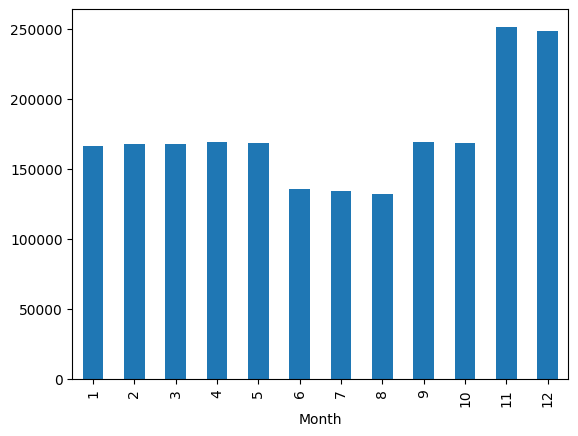

In [87]:
units_month.plot(kind = 'bar')

In [88]:
capacity_month = [CAPACITY]*12

stock_needed = {}
need = 0
for month in range(12, 0, -1):               # 12, 11, ..., 1
    need = max(0, need + units_month[month] - capacity_month[month - 1])
    print(month, need)
    stock_needed[month] = need

12 58353.79999999999
11 119833.79999999999
10 98665.19999999995
9 77888.19999999995
8 19897.399999999965
7 0
6 0
5 0
4 0
3 0
2 0
1 0


In [89]:
start = 0
full_month_names = ['January', 'February', 'March', 'April', 'May', 'June',
                    'July', 'August', 'September', 'October', 'November',
                    'December']
for month in range(1, 12):
    if stock_needed[month] == 0:
        start = month
print('Decision: start building in', full_month_names[start - 1])
print(f'Units in the warehouse on 1 November: {round(stock_needed[11]):,}')

Decision: start building in July
Units in the warehouse on 1 November: 119,834


### 1.3 Retire SKU-9325?

**Sophie's rule:** retire it only if the savings are larger than the margin we would lose: on SKU-9325 itself, plus on the other parts in the orders that the four wholesalers would move.

In [93]:
year_df = df[df['Year'] == last]
part_margin = year_df[year_df['SKU_Name'] == PART]['Sales'].sum()* MARGIN
part_margin

np.float64(112313.64024138426)

In [94]:
year_df = df[df['Year'] == last]

part_margin = year_df[year_df['SKU_Name'] == PART]['Sales'].sum()* MARGIN

orders_with_part = year_df[year_df['SKU_Name'] == PART]['Order_ID'].unique()

in_orders = year_df[year_df['Order_ID'].isin(orders_with_part)]

moved = in_orders[
    in_orders['Location'].isin(MOVERS) & (in_orders['SKU_Name'] != PART)
]


In [95]:
moved_by_wholesaler = moved.pivot_table(
    values='Sales',
    index='Location',
    aggfunc='sum'
)
moved_by_wholesaler['Margin'] = moved_by_wholesaler['Sales'] * MARGIN
moved_by_wholesaler.round()

,Sales,Margin
Location,,
Bourgeois,38205.0,11462.0
Bruneau Coulon S.A.,40459.0,12138.0
De Sousa,44222.0,13266.0
Pichon,376198.0,112859.0


In [96]:
lost = part_margin + moved_by_wholesaler['Margin'].sum()
print(f'Savings: €{SAVINGS:,} | margin we would lose: €{lost:,.0f}')
print(
    f'Savings minus the margin on {PART} alone (what Antoine sees): '
    f'€{SAVINGS - part_margin:,.0f}'
)

if SAVINGS > lost:
    print('Decision: retire', PART)
else:
    print('Decision: keep', PART)

Savings: €150,000 | margin we would lose: €262,039
Savings minus the margin on SKU-9325 alone (what Antoine sees): €37,686
Decision: keep SKU-9325


In [97]:
print(f'Margin on {PART} alone: €{part_margin:,.0f}')
print(f'Savings minus the margin we would lose: {SAVINGS - lost:,.0f} €')

Margin on SKU-9325 alone: €112,314
Savings minus the margin we would lose: -112,039 €


### 1.4 Sign the backup agreement for Carpentier?

**Sophie's rule:** sign it only if the margin it is expected to save is larger than its cost.

In [98]:
wholesaler_sales = year_df[year_df['Location'] == WHOLESALER]['Sales'].sum()


In [99]:
region = year_df[year_df['Location'] == WHOLESALER]['region'].iloc[0]
region_df = year_df[year_df['region'] == region]

share_company = wholesaler_sales / year_df['Sales'].sum() * 100
share_region = wholesaler_sales / region_df['Sales'].sum() * 100
print(
    f'{WHOLESALER}: {round(share_company, 1)}% of our revenue, '
    f'{round(share_region, 1)}% of {region}'
)

Carpentier: 2.4% of our revenue, 37.6% of Bourgogne-Franche-Comté


In [100]:
margin_at_stake = wholesaler_sales * MARGIN
no_agreement = FAIL_PROB * margin_at_stake * (1 - KEEP_WITHOUT)
agreement = BACKUP_COST + FAIL_PROB * margin_at_stake * (1 - KEEP_WITH)
print(
    f'Expected cost, without the agreement: €{no_agreement:,.0f} '
    f'| with it: €{agreement:,.0f}'
)

Expected cost, without the agreement: €33,227 | with it: €24,494


In [101]:
breakeven = BACKUP_COST / (margin_at_stake * (KEEP_WITH - KEEP_WITHOUT))
print(f'Worth signing if the chance of failing is above {breakeven * 100:.1f}%')

Worth signing if the chance of failing is above 15.8%


In [102]:
no_agreement_be = breakeven * margin_at_stake * (1 - KEEP_WITHOUT)
agreement_be = BACKUP_COST + breakeven * margin_at_stake * (1 - KEEP_WITH)
print(
    f'At {breakeven * 100:.1f}%: without the agreement '
    f'€{no_agreement_be:,.0f} | with it €{agreement_be:,.0f}'
)

At 15.8%: without the agreement €21,000 | with it €21,000


In [103]:
if agreement < no_agreement:
    print('Decision: sign the agreement')
else:
    print('Decision: do not sign')

Decision: sign the agreement


## Step 2. Charts a manager reads in seconds

These charts use what you learned in the plotting lessons (`bar`, `barh`, `subplots`, titles, colours, `set_ylim`), plus a few small tools explained in the comments.

Four principles. The full topic comes in the Data Storytelling week.

1. **The title says the finding**, not the topic: "November and December bring X% of the year's revenue", not "Monthly sales".
2. **Cut the clutter**: no frame, no grid, no axis you don't need. Put the values on the bars.
3. **One colour for what matters**, grey or light for the rest.
4. **Bars start at zero**, or the chart exaggerates the differences.

### 2.1 Exploring vs presenting

In the case we zoomed the axis to see small differences: that helps while **exploring**. When we **present** to a manager, bars start at zero. Same data, two very different impressions:

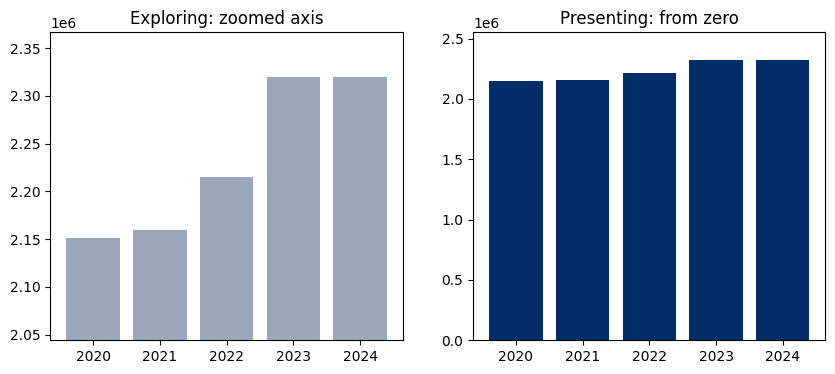

In [104]:
# the colours used in all the charts
DARK = '#012d69'     # for what matters
LIGHT = '#c9d5ea'    # for the rest
GREY = '#9aa7bb'     # for what we compare with

# revenue of the top part of each year
top_part_revenue = df.pivot_table(
    values='Sales',
    index='SKU_Name',
    columns='Year',
    aggfunc='sum'
).max()

# two charts side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.bar(top_part_revenue.index, top_part_revenue.values, color=GREY)
# zoomed axis, like while exploring
ax1.set_ylim(top_part_revenue.min() * 0.95, top_part_revenue.max() * 1.02)
ax1.set_title('Exploring: zoomed axis')

ax2.bar(top_part_revenue.index, top_part_revenue.values, color=DARK)
# from zero, for a manager
ax2.set_ylim(0, top_part_revenue.max() * 1.1)
ax2.set_title('Presenting: from zero')

plt.show()

### 2.2 Decision 1: revenue and units, side by side

Revenue and units sold have different units, so we draw two charts side by side, both from zero. `ax.text()` writes the value on each bar.

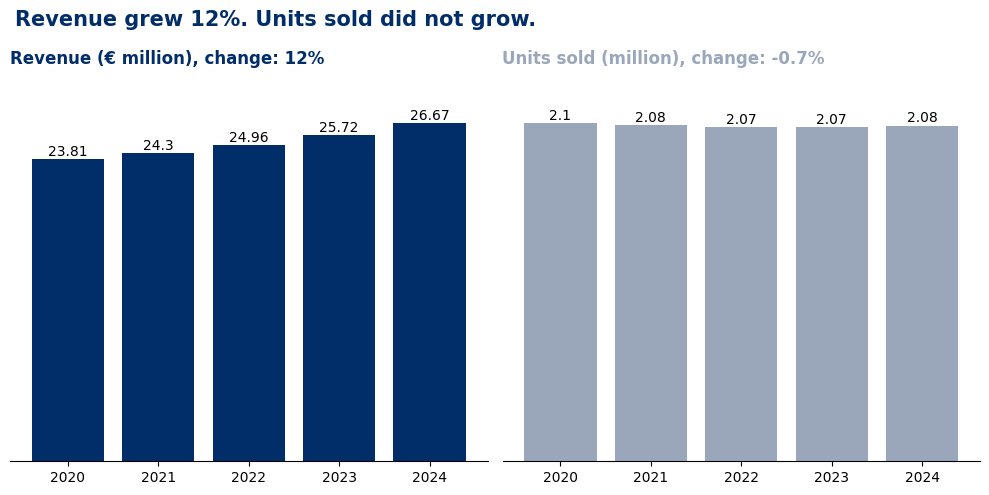

In [105]:
# years as text, so the axis shows 2020, 2021...
years = [str(y) for y in yearly.index]
revenue_m = yearly['Sales'] / 1000000            # revenue in millions
units_m = yearly['Quantity'] / 1000000           # units in millions

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# left: revenue
ax1.bar(years, revenue_m, color=DARK)
for i in range(len(years)):
    # value on top of each bar
    ax1.text(
        i, revenue_m.iloc[i] * 1.01,
        round(revenue_m.iloc[i], 2),
        ha='center'
    )
ax1.set_ylim(0, revenue_m.max() * 1.15)          # from zero
ax1.set_title(
    f'Revenue (€ million), change: {round(revenue_change)}%',
    loc='left', color=DARK, fontweight='bold'
)

# right: units sold
ax2.bar(years, units_m, color=GREY)
for i in range(len(years)):
    ax2.text(
        i, units_m.iloc[i] * 1.01,
        round(units_m.iloc[i], 2),
        ha='center'
    )
ax2.set_ylim(0, units_m.max() * 1.15)
ax2.set_title(
    f'Units sold (million), change: {round(units_change, 1)}%',
    loc='left', color=GREY, fontweight='bold'
)

# cut the clutter: no y axis (the values are on the bars) and no frame
for ax in [ax1, ax2]:
    ax.set_yticks([])
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)

# the title of the whole figure says the finding
fig.suptitle(
    f'Revenue grew {round(revenue_change)}%. Units sold did not grow.',
    x=0.02, ha='left', fontsize=15, fontweight='bold', color=DARK
)
plt.tight_layout()
# save it for your page
plt.savefig('chart_1_revenue_units.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.3 Decision 2: units against capacity, with the start of the build

`axhline()` draws the capacity, `axvline()` the start of the build, and `annotate()` writes a label with an arrow.

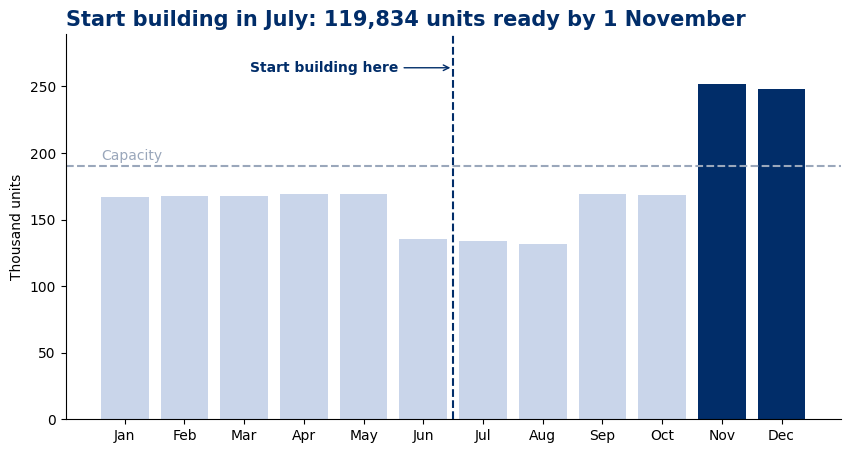

In [106]:
values = units_month / 1000     # units in thousands

# dark for the months above capacity, light for the rest
colors = []
for m in units_month.index:
    if units_month[m] > CAPACITY:
        colors.append(DARK)
    else:
        colors.append(LIGHT)

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(month_names, values, color=colors)

# the capacity: a dashed horizontal line
ax.axhline(CAPACITY / 1000, color=GREY, linestyle='--')
ax.text(-0.4, CAPACITY / 1000 + 5, 'Capacity', color=GREY)

# the action: a dashed line half a bar before the start month
# (the bars are at 0 to 11), and a label with an arrow
line_x = start - 1.5
ax.axvline(line_x, color=DARK, linestyle='--')
ax.annotate(
    'Start building here',
    xy=(line_x, values.max() * 1.05),
    xytext=(line_x - 3.4, values.max() * 1.05),
    va='center', color=DARK, fontweight='bold',
    arrowprops=dict(arrowstyle='->', color=DARK)
)

ax.set_ylim(0, values.max() * 1.15)     # from zero
ax.set_ylabel('Thousand units')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title(
    f'Start building in {full_month_names[start - 1]}: '
    f'{round(stock_needed[11]):,} units ready by 1 November',
    loc='left', fontsize=15, fontweight='bold', color=DARK
)
plt.savefig('chart_2_peak_stock.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.4 Decision 3: what we save against what we lose

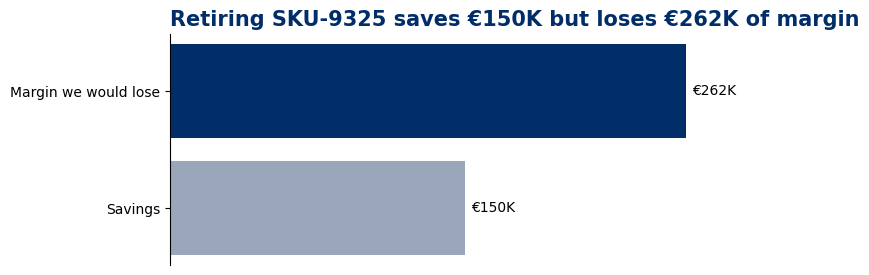

In [107]:
labels = ['Savings', 'Margin we would lose']
amounts = [SAVINGS / 1000, lost / 1000]     # in thousand €

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(labels, amounts, color=[GREY, DARK])
for i in range(len(amounts)):
    # the value at the end of each bar
    ax.text(amounts[i] + 3, i, f'€{round(amounts[i])}K', va='center')

ax.set_xlim(0, max(amounts) * 1.2)
ax.set_xticks([])                     # the values are on the bars
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_title(
    f'Retiring {PART} saves €{round(SAVINGS / 1000)}K '
    f'but loses €{round(lost / 1000)}K of margin',
    loc='left', fontsize=15, fontweight='bold', color=DARK
)
plt.savefig('chart_3_retire_part.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.5 Decision 4: Carpentier in the company and in its region

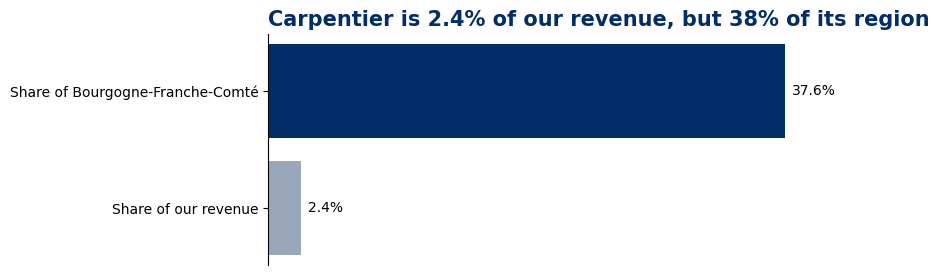

In [108]:
labels = ['Share of our revenue', f'Share of {region}']
shares = [share_company, share_region]

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(labels, shares, color=[GREY, DARK])
for i in range(len(shares)):
    ax.text(shares[i] + 0.5, i, f'{round(shares[i], 1)}%', va='center')

ax.set_xlim(0, max(shares) * 1.2)
ax.set_xticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_title(
    f'{WHOLESALER} is {round(share_company, 1)}% of our revenue, '
    f'but {round(share_region)}% of its region',
    loc='left', fontsize=15, fontweight='bold', color=DARK
)
plt.savefig('chart_4_exposure.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 3. What goes on your project page

- One answer per decision: the decision as the heading, then the two or three numbers that support it (from **this** notebook), the chart, and what the data can't tell (only if it matters). Keep it short.
- The four charts you saved (`chart_1` to `chart_4`).

**Before you publish, check your page against this notebook:**
- Every number on the page appears in an output above. If you can't point to the output, don't use the number.
- When you write "at most", "every year" or "less than", check the largest or smallest value, not the average.

**What else could you add?** With the tools you already have, what is one more question that would make this project more useful? If you answer it, add it as a finding. If not, put it under "what needs further investigation".

## Step 4. Numbers for your issue log

Your technical page has an issue log: one row for each problem you found in the data, with how many lines it touched. Some counts are already printed in the case (for example 2,986 blank sales and 6,541 missing sales in total). These cells print the others.

The case cleaned `df` step by step, so the raw values are gone. We read the raw files again, under new names (`raw_list` and `raw`), so `df` stays as it is.

In [109]:
# read the raw files again, under new names, so the clean df stays as it is
raw_list = list()
for file, year in files.items():
  xls = pd.ExcelFile(file)
  for month in range(1, 13):
    tab = pd.read_excel(xls, sheet_name=f'Month_{month}')
    raw_list.append(tab)
raw = pd.concat(raw_list, ignore_index=True)
print('Lines in the raw files:', len(raw))

Lines in the raw files: 396978


In [110]:
# 1. sales typed as text ("missing", "na", "-"...):
#    missing after the replace, but not blank in the raw files
raw_sales = raw['Sales'].replace(unique_text_values, np.nan).astype(float)
print(
    'Sales typed as text:',
    raw_sales.isna().sum() - raw['Sales'].isna().sum()
)

# 2. part codes written with "@" or "_fr": the lines that fix_sku_name changes
print(
    'Lines with "@" or "_fr" in the part code:',
    (raw['SKU_Name'] != raw['SKU_Name'].apply(fix_sku_name)).sum()
)

# 3. lines with quantity 0
print('Lines with quantity 0:', (raw['Quantity'] == 0).sum())

# 4. revenue added by filling the missing sales
#    = total after filling - sales that were already there
filled = df['Sales'].sum() - raw_sales.sum()
print(
    f'Revenue added by filling the missing sales: '
    f'€{filled:,.0f} of €{df["Sales"].sum():,.0f}'
)

# 5. the join with stores.xlsx must not add or lose lines
print('Lines after the join:', len(df))
print('Lines without a region:', df['region'].isna().sum())

/tmp/ipykernel_1578/3266293741.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  raw_sales = raw['Sales'].replace(unique_text_values, np.nan).astype(float)


Sales typed as text: 3555
Lines with "@" or "_fr" in the part code: 11835
Lines with quantity 0: 1939
Revenue added by filling the missing sales: €2,080,234 of €125,454,591
Lines after the join: 396978
Lines without a region: 0
